# Multi-Agent Software Engineering Team

A coordinator routes a software task to specialist agents (requirements, architect, code engineer, test engineer, reviewer).
**Real `pytest` execution, not an LLM's claim, decides whether the code passes.** All work happens in a temp copy of the repo.

Sections: 1. Setup · 2. `solve()` interface · 3. Greenfield demo · 4. Existing-repo demo · 5. Benchmark (baseline vs fixed vs routed) · 6. Charts & cost breakdown

## 1. Setup

In [1]:
import sys, os, json
sys.path.insert(0, os.getcwd())
from swe_team.llm import BedrockClient
from swe_team.agents import Budget
from swe_team.coordinator import Coordinator
from swe_team.baseline import run_baseline

llm = BedrockClient(region="us-east-1")   # swap for any object with .complete(system, prompt, ...)

## 2. Interface

`solve(task, repo=None, mode=...)`: `mode` is `"routed"` (coordinator picks specialists), `"fixed"` (all five, always) or `"baseline"` (single agent).
`repo` is a path to an existing local repository (copied, never modified); leave `None` for greenfield.

In [2]:
import pandas as pd

def solve(task, repo=None, mode="routed", max_revisions=2, max_cost_usd=1.0, show_files=True):
    budget = Budget(max_calls=25, max_cost_usd=max_cost_usd, max_seconds=900)
    if mode == "baseline":
        res = run_baseline(task, llm, repo, max_revisions, budget)
        res.steps, res.error = ["solo"], None
    else:
        res = Coordinator(llm, mode, max_revisions, budget, on_event=lambda m: print("  ·", m)).run(task, repo)
    print(); print(f"steps: {'+'.join(res.steps)} | revisions: {res.revisions} | calls: {budget.calls} | "
          f"tokens: {budget.input_tokens}+{budget.output_tokens} | cost: ${budget.cost_usd:.4f}")
    if res.error: print("ERROR:", res.error)
    if res.report: print(f"tests: {'PASS' if res.report.ok else 'FAIL'} ({res.report.passed} passed, {res.report.failed} failed)")
    if getattr(res, "review", None): print(f"review: approved={res.review.approved}, findings={len(res.review.findings)}")
    if show_files:
        for f in res.workspace.files():
            print(); print(f"--- {f}"); print(res.workspace.read_file(f))
    print(); print("workspace:", res.workspace.root)
    return res

## 3. Greenfield demo

In [3]:
res = solve("Create a Python module stack_calc.py with evaluate_rpn(tokens: list[str]) -> float that evaluates "
            "Reverse Polish Notation with + - * /. Raise ValueError on malformed input and ZeroDivisionError on division by zero.")

  · plan: ['requirements', 'engineer', 'tester', 'reviewer'] (simple) - The task is straightforward with clear specifications (RPN evaluation, specific operators, error handling), but requires clarification on edge cases (empty input, single token, whitespace handling) before implementation. Testing is essential to verify correctness of the algorithm and error conditions.
  · requirements done
  · engineer done
  · tester done
  · iteration 0: tests ok=False passed=13 failed=1
  · iteration 1: tests ok=False passed=25 failed=1
  · iteration 2: tests ok=False passed=13 failed=1

steps: requirements+engineer+tester+reviewer | revisions: 2 | calls: 7 | tokens: 14400+8539 | cost: $0.1185
tests: FAIL (13 passed, 1 failed)

--- stack_calc.py
def evaluate_rpn(tokens: list[str]) -> float:
    """Evaluate a mathematical expression in Reverse Polish Notation.
    
    Args:
        tokens: A list of string tokens representing numbers and operators (+, -, *, /)
        
    Returns:
        float

## 4. Existing-repository demo
The fixture repo is copied; the original stays untouched.

In [4]:
res = solve("In the existing cart.py add apply_coupon(total, code): SAVE10 = 10% off, SAVE20 = 20% off, "
            "rounded to 2 decimals, unknown codes raise ValueError. Keep total() working.",
            repo="benchmarks/fixtures/shop_repo")

  · plan: ['engineer', 'tester', 'reviewer'] (simple) - This is a straightforward feature addition to an existing file with clear, unambiguous requirements (two coupon codes with fixed discounts). The engineer implements the function, tester verifies the discount logic and error handling, and reviewer ensures the implementation doesn't break existing total() functionality and handles edge cases correctly.
  · engineer done
  · tester done
  · iteration 0: tests ok=False passed=1 failed=1
  · iteration 1: tests ok=False passed=5 failed=1
  · iteration 2: tests ok=False passed=2 failed=1

steps: engineer+tester+reviewer | revisions: 2 | calls: 5 | tokens: 7598+10629 | cost: $0.1463
tests: FAIL (2 passed, 1 failed)

--- cart.py
from decimal import Decimal, ROUND_HALF_UP


def total(items):
    """items: list of (name, unit_price, quantity). Returns the cart total."""
    result = sum(Decimal(str(price)) * Decimal(str(qty)) for _, price, qty in items)
    return float(result.quantize(Decim

## 5. Benchmark: three configurations
Each task is scored by **hidden acceptance tests the agents never see**. 4 tasks × 3 configs = 12 live runs (a few dollars at most; each run is capped by `Budget`).
Results are cached to `benchmark_results.csv`; delete it to re-run.

In [5]:
from swe_team.evaluate import run_benchmark, summarize, TASKS
CACHE = "benchmark_results.csv"
if os.path.exists(CACHE):
    df = pd.read_csv(CACHE)
else:
    df = run_benchmark(llm, budget_kwargs=dict(max_calls=25, max_cost_usd=1.0, max_seconds=900))
    df.to_csv(CACHE, index=False)
df

RuntimeError: AWS credentials problem, aborting benchmark (not a task failure): ClientError: An error occurred (ExpiredTokenException) when calling the Converse operation: The security token included in the request is expired

In [ ]:
summarize(df)

,pass_rate,hidden_test_pass,hidden_test_total,failure_rate,avg_cost_usd,avg_tokens,avg_wall_s,avg_calls,avg_revisions
config,,,,,,,,,
baseline,0.75,16,16,0.25,0.039,3297.25,26.075,1.0,0.25
fixed,0.75,16,16,0.25,0.081,8374.00,50.025,4.0,0.00
routed,0.25,5,5,0.75,0.071,11949.75,157.275,4.0,0.50


## 6. Charts

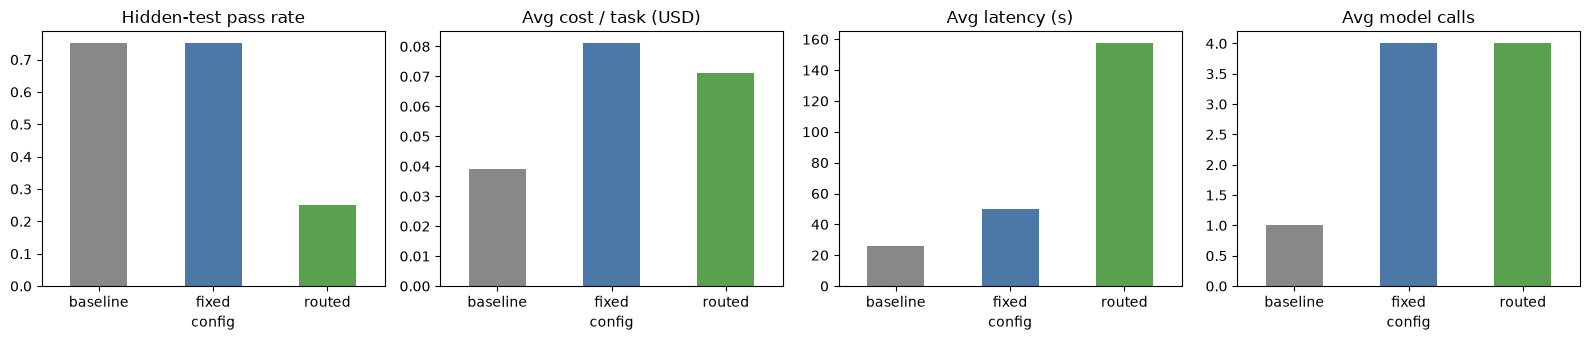

In [ ]:
import matplotlib.pyplot as plt
s = summarize(df)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, col, title in zip(ax, ["pass_rate", "avg_cost_usd", "avg_wall_s", "avg_calls"],
                         ["Hidden-test pass rate", "Avg cost / task (USD)", "Avg latency (s)", "Avg model calls"]):
    s[col].plot.bar(ax=a, color=["#888", "#4c78a8", "#59a14f"], rot=0); a.set_title(title)
plt.tight_layout(); plt.show()

Cost breakdown by agent for the last interactive run:

In [ ]:
pd.DataFrame(res.budget.log).groupby("agent")[["in", "out", "cost", "latency"]].sum().round(4)

,in,out,cost,latency
agent,,,,
engineer,3680,1144,0.0282,15.0935
reviewer,1498,223,0.0026,1.9038
router,339,104,0.0009,1.6578
tester,554,3371,0.0174,13.8553
